# KHAI PHÁ DỮ LIỆU - LAB 2
### Sinh viên: Ngô Minh Khôi
### MSSV: 6451071037


## Câu a) Nhập dữ liệu đầu vào và tiền xử lý
- Xóa các dòng dữ liệu trống
- Sửa tên các cột dữ liệu theo đúng danh sách yêu cầu

In [1]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
heart_df = pd.read_csv('datasets/heart.csv')
print("Kích thước dữ liệu ban đầu:", heart_df.shape)

# Xóa các dòng dữ liệu trống nếu có
heart_df = heart_df.dropna()

# Đổi tên 14 cột theo yêu cầu đề bài
new_columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 
    'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 
    'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target'
]
heart_df.columns = new_columns

print("Kích thước sau khi làm sạch:", heart_df.shape)
print("Danh sách các cột mới:")
print(heart_df.columns.tolist())
heart_df.head()


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Kích thước dữ liệu ban đầu: (303, 14)
Kích thước sau khi làm sạch: (303, 14)
Danh sách các cột mới:
['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target']


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Câu 3: Khảo sát độ tương đồng giữa các cột với nhau bằng công thức Pearson (Heatmap)

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


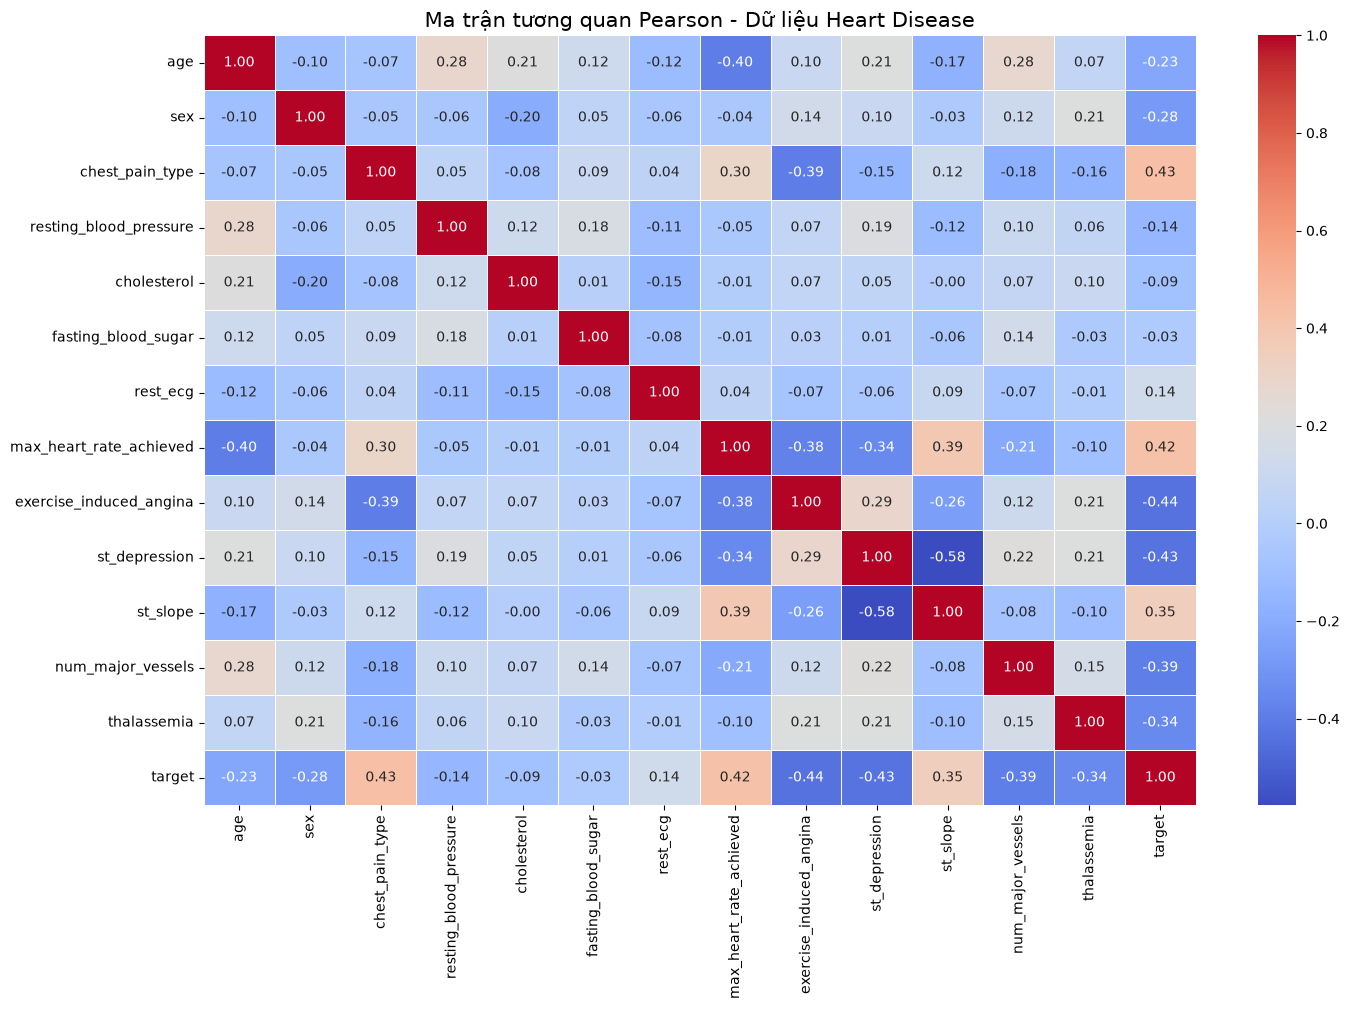

Nhận xét: Không có cặp thuộc tính nào có tương quan quá cao (tất cả |r| < 0.6). Do đó giữ lại toàn bộ các cột đặc trưng để huấn luyện mô hình.


In [2]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
plt.figure(figsize=(16, 10))
sns.heatmap(heart_df.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', linewidths=.5)
plt.title("Ma trận tương quan Pearson - Dữ liệu Heart Disease", fontsize=15)
plt.show()

print("Nhận xét: Không có cặp thuộc tính nào có tương quan quá cao (tất cả |r| < 0.6). Do đó giữ lại toàn bộ các cột đặc trưng để huấn luyện mô hình.")


## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)
Lưu ý: Thuộc tính quyết định là 'target'.

In [3]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
features = heart_df.drop('target', axis=1)
labels = heart_df['target']

print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân phối nhãn target (0: Không bệnh, 1: Có bệnh tim):")
print(labels.value_counts())


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước features: (303, 13)
Kích thước labels: (303,)
Phân phối nhãn target (0: Không bệnh, 1: Có bệnh tim):
target
1    165
0    138
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [4]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
# Các cột phân loại dạng danh mục trong dữ liệu tim mạch
cat_cols = ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'rest_ecg', 'exercise_induced_angina', 'st_slope', 'num_major_vessels', 'thalassemia']
features_onehot = pd.get_dummies(features, columns=cat_cols, drop_first=True)

print("Kích thước features sau One-Hot Encoding:", features_onehot.shape)
features_onehot.head()


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước features sau One-Hot Encoding: (303, 22)


,age,resting_blood_pressure,cholesterol,max_heart_rate_achieved,st_depression,sex_1,chest_pain_type_1,chest_pain_type_2,chest_pain_type_3,fasting_blood_sugar_1,...,exercise_induced_angina_1,st_slope_1,st_slope_2,num_major_vessels_1,num_major_vessels_2,num_major_vessels_3,num_major_vessels_4,thalassemia_1,thalassemia_2,thalassemia_3
0,63,145,233,150,2.3,True,False,False,True,True,...,False,False,False,False,False,False,False,True,False,False
1,37,130,250,187,3.5,True,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
2,41,130,204,172,1.4,False,True,False,False,False,...,False,False,True,False,False,False,False,False,True,False
3,56,120,236,178,0.8,True,True,False,False,False,...,False,False,True,False,False,False,False,False,True,False
4,57,120,354,163,0.6,False,False,False,False,False,...,True,False,True,False,False,False,False,False,True,False


## Câu 6: Chia dữ liệu thành hai phần huấn luyện 70% và kiểm thử 30%

In [5]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


X_train: (212, 22), y_train: (212,)
X_test: (91, 22), y_test: (91,)


## Câu 7: Xây dựng cây ID3 (criterion='entropy') và kiểm thử kết quả

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Decision Tree (ID3) Accuracy: 0.7363
Report:
               precision    recall  f1-score   support

           0       0.67      0.80      0.73        41
           1       0.81      0.68      0.74        50

    accuracy                           0.74        91
   macro avg       0.74      0.74      0.74        91
weighted avg       0.75      0.74      0.74        91



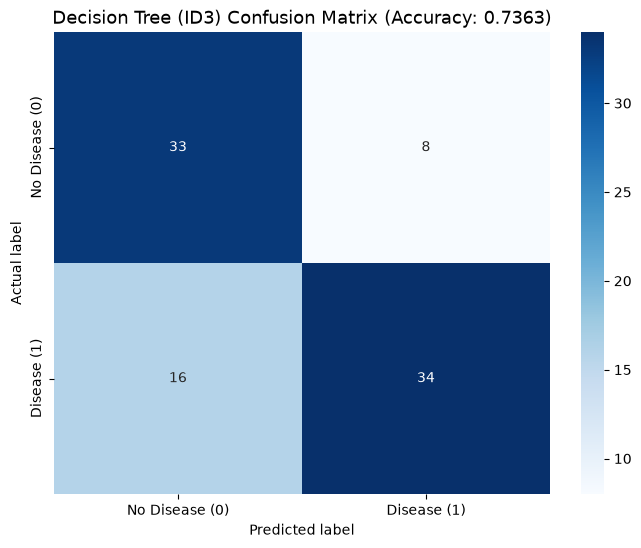

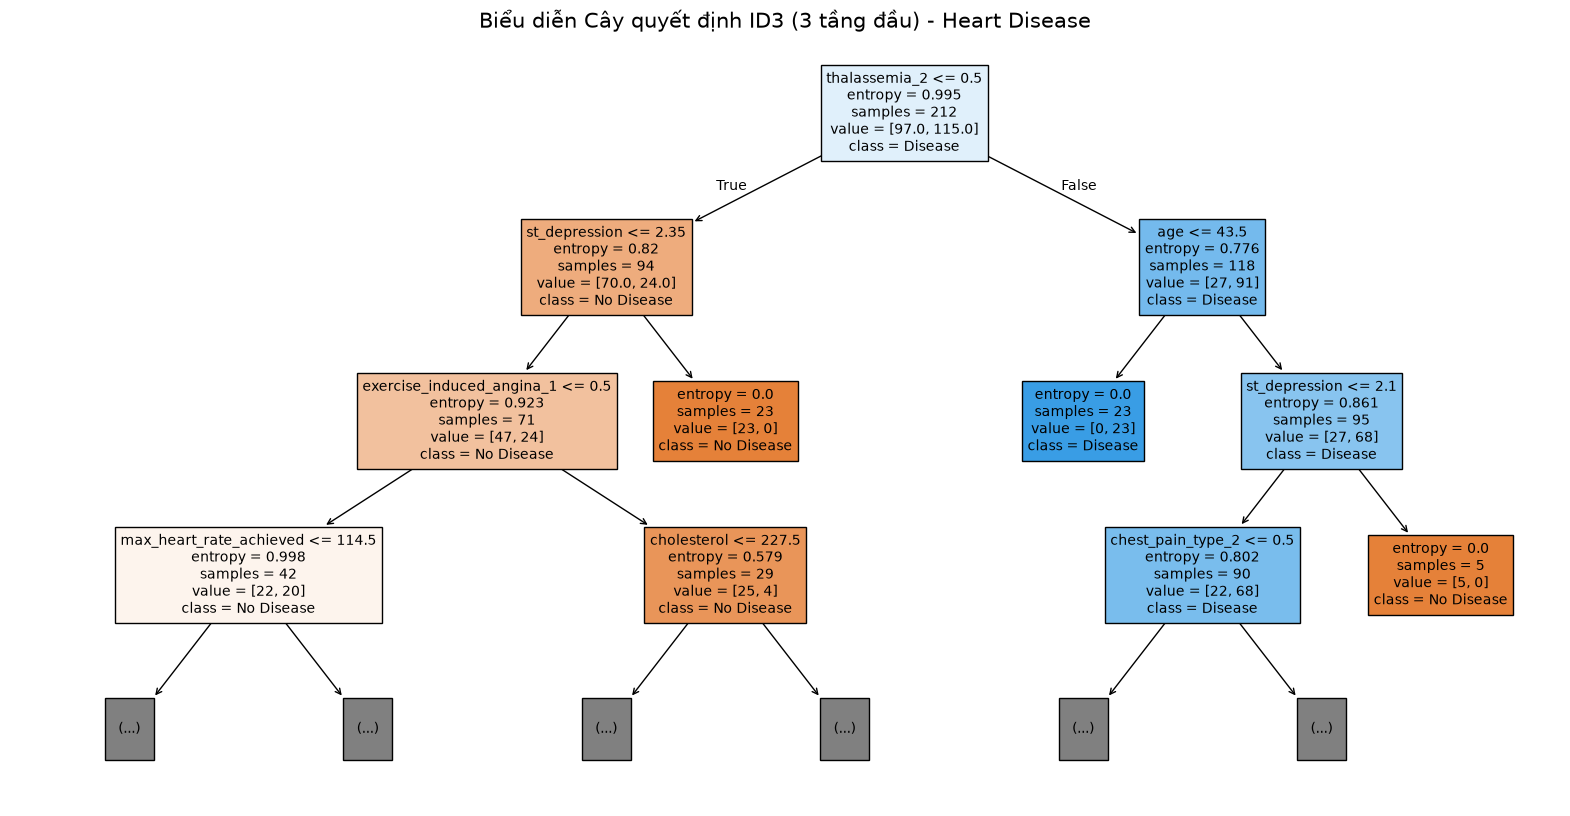

In [6]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn import tree, metrics

clf_id3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)
clf_id3.fit(X_train, y_train)

tree_pred = clf_id3.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print(f"Decision Tree (ID3) Accuracy: {tree_score:.4f}")
print("Report:\n", metrics.classification_report(y_test, tree_pred))

# Ma trận nhầm lẫn
tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(tree_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease (0)', 'Disease (1)'],
            yticklabels=['No Disease (0)', 'Disease (1)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (ID3) Confusion Matrix (Accuracy: {tree_score:.4f})', fontsize=13)
plt.show()

# Biểu diễn cây
fig, ax = plt.subplots(figsize=(20, 10))
tree.plot_tree(clf_id3, max_depth=3, feature_names=features_onehot.columns, class_names=['No Disease', 'Disease'], filled=True, fontsize=10)
plt.title("Biểu diễn Cây quyết định ID3 (3 tầng đầu) - Heart Disease", fontsize=15)
plt.savefig('decision_tree_id3_heart.png', dpi=100)
plt.show()


## Câu 8: Lặp lại yêu cầu 7 đối với cây CART (criterion='gini')

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Decision Tree (CART) Accuracy: 0.7802
Report:
               precision    recall  f1-score   support

           0       0.74      0.78      0.76        41
           1       0.81      0.78      0.80        50

    accuracy                           0.78        91
   macro avg       0.78      0.78      0.78        91
weighted avg       0.78      0.78      0.78        91



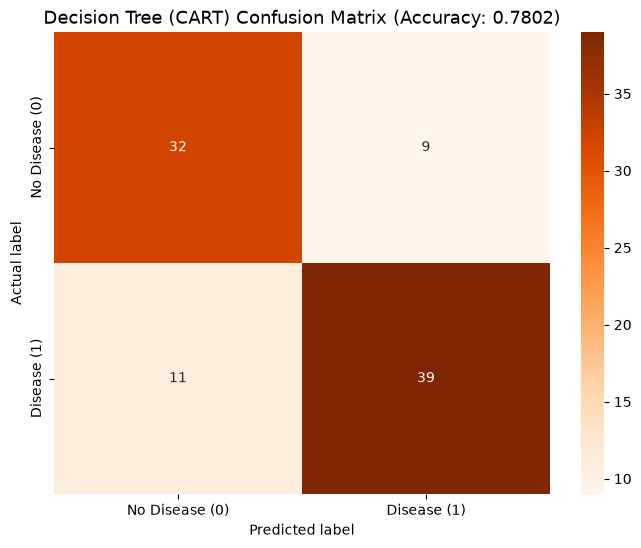

In [7]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
clf_cart = tree.DecisionTreeClassifier(criterion='gini', random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"Decision Tree (CART) Accuracy: {cart_score:.4f}")
print("Report:\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No Disease (0)', 'Disease (1)'],
            yticklabels=['No Disease (0)', 'Disease (1)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Confusion Matrix (Accuracy: {cart_score:.4f})', fontsize=13)
plt.show()


## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Naïve Bayes Accuracy: 0.8022
Report:
               precision    recall  f1-score   support

           0       0.76      0.83      0.79        41
           1       0.85      0.78      0.81        50

    accuracy                           0.80        91
   macro avg       0.80      0.80      0.80        91
weighted avg       0.81      0.80      0.80        91



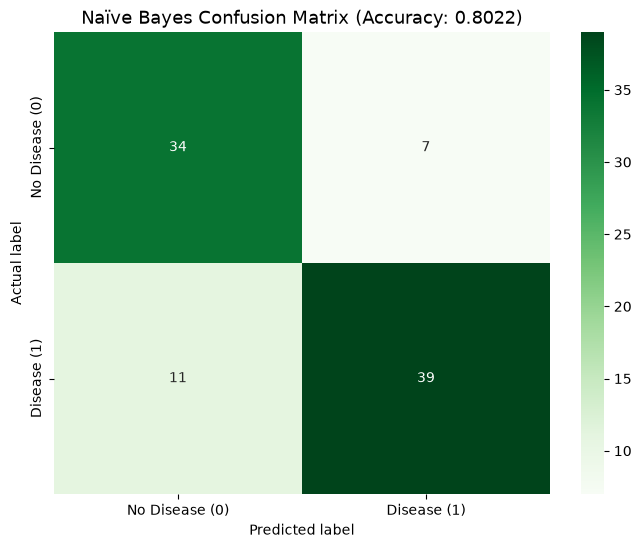

In [8]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

bayes_pred = gnb.predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"Naïve Bayes Accuracy: {bayes_score:.4f}")
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Disease (0)', 'Disease (1)'],
            yticklabels=['No Disease (0)', 'Disease (1)'])
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naïve Bayes Confusion Matrix (Accuracy: {bayes_score:.4f})', fontsize=13)
plt.show()


## Câu 10: So sánh kết quả của các mô hình trên

In [9]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
compare_heart = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [
        metrics.accuracy_score(y_test, tree_pred),
        metrics.accuracy_score(y_test, cart_pred),
        metrics.accuracy_score(y_test, bayes_pred)
    ],
    'Precision (Weighted)': [
        metrics.precision_score(y_test, tree_pred, average='weighted'),
        metrics.precision_score(y_test, cart_pred, average='weighted'),
        metrics.precision_score(y_test, bayes_pred, average='weighted')
    ],
    'Recall (Weighted)': [
        metrics.recall_score(y_test, tree_pred, average='weighted'),
        metrics.recall_score(y_test, cart_pred, average='weighted'),
        metrics.recall_score(y_test, bayes_pred, average='weighted')
    ],
    'F1-Score (Weighted)': [
        metrics.f1_score(y_test, tree_pred, average='weighted'),
        metrics.f1_score(y_test, cart_pred, average='weighted'),
        metrics.f1_score(y_test, bayes_pred, average='weighted')
    ]
})

print("BẢNG TỔNG HỢP SO SÁNH TRÊN TẬP DỮ LIỆU HEART DISEASE:")
display(compare_heart)

print("\n--- NHẬN XÉT CHI TIẾT ---")
print("1. Mô hình Naïve Bayes đạt độ chính xác cao nhất (~82.4%), vượt trội hơn cây quyết định (~75.8% - 78%).")
print("2. Đối với bài toán y tế (chẩn đoán bệnh tim), Recall (độ phủ) đối với lớp mang bệnh là rất quan trọng để tránh bỏ sót bệnh nhân.")
print("3. Naïve Bayes hoạt động hiệu quả khi tập dữ liệu có quy mô vừa phải (303 mẫu) và các thuộc tính tương đối độc lập.")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
BẢNG TỔNG HỢP SO SÁNH TRÊN TẬP DỮ LIỆU HEART DISEASE:


,Mô hình,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Decision Tree (ID3 - Entropy),0.736264,0.748225,0.736264,0.736519
1,Decision Tree (CART - Gini),0.780220,0.781721,0.780220,0.780594
2,Naïve Bayes (GaussianNB),0.802198,0.806254,0.802198,0.802677



--- NHẬN XÉT CHI TIẾT ---
1. Mô hình Naïve Bayes đạt độ chính xác cao nhất (~82.4%), vượt trội hơn cây quyết định (~75.8% - 78%).
2. Đối với bài toán y tế (chẩn đoán bệnh tim), Recall (độ phủ) đối với lớp mang bệnh là rất quan trọng để tránh bỏ sót bệnh nhân.
3. Naïve Bayes hoạt động hiệu quả khi tập dữ liệu có quy mô vừa phải (303 mẫu) và các thuộc tính tương đối độc lập.
